# Data validation and anomaly detection at ingestion

**Module 05 — Secure Data Management and Dataset Protection**

A poisoned dataset (Module 07) usually arrives looking like a dataset: right columns, plausible rows, one
or two values that could not occur. This notebook builds the validation gate that runs before training:
schema checks, range checks, duplicate detection and multivariate outliers, with every finding recorded as
evidence rather than a printed warning.

## Learning objectives

1. Express a data contract as executable checks rather than prose.
2. Distinguish schema violations, domain violations and statistical anomalies.
3. Detect duplicates and near-duplicates, and explain why they matter for poisoning.
4. Rank suspicious rows with an unsupervised outlier score and interpret the score's limits.
5. Produce a validation report an ingestion job can refuse to proceed on.

## Background

Three kinds of check, in increasing cost and decreasing precision:

* **Schema** — column presence, dtype, nullability. Cheap, exact.
* **Domain** — allowed values, ranges, referential integrity. Cheap, exact against a stated contract.
* **Statistical** — distributional anomalies, multivariate outliers. Expensive, heuristic, and the only
  kind that can catch a *plausible* poisoned row.

The last one is where the interesting failures live, and it is the one that produces false positives. A
report that says "17 rows suspicious" is only useful if it also says what the detector assumes.

## Dependencies and installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "scikit-learn>=1.4" "matplotlib>=3.9"
```

CPU, a few seconds, no network.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

SEED = 13
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 120)
print("ready")

ready


**Expected output** — `ready`.

### Step 1 — A clean batch, then a corrupted one

The clean batch follows a simple generative story. The corrupted batch adds the four failures that real
pipelines see: an impossible value, a duplicated record, an unknown category, and a row that is
statistically odd but individually legal.

In [2]:
def make_batch(n=400, corrupt=False):
    age = rng.normal(55, 14, n).round().clip(18, 95)
    bmi = rng.normal(27, 4, n).round(1)
    label = (age + rng.normal(0, 10, n) > 60).astype(int)
    df = pd.DataFrame(
        {
            "record_id": [f"R{i:04d}" for i in range(n)],
            "age": age.astype(int),
            "bmi": bmi,
            "site": rng.choice(["north", "south", "east"], n),
            "label": label,
        }
    )
    if corrupt:
        df.loc[0, "age"] = 999                     # impossible domain value
        df.loc[1, "site"] = "north "               # trailing space, new category
        df = pd.concat([df, df.iloc[[2]]], ignore_index=True)   # exact duplicate
        df.loc[3, ["age", "bmi", "label"]] = [30, 62.0, 0]      # legal values, odd combination
    return df


clean = make_batch()
dirty = make_batch(corrupt=True)
print("clean rows:", len(clean), "| dirty rows:", len(dirty))

clean rows: 400 | dirty rows: 401


**Expected output** — 400 clean rows and 401 dirty rows (the duplicate adds one). Nothing about the dirty
batch looks anomalous in a preview, which is the point.

### Step 2 — The contract, as code

The contract is a dictionary so that it can be versioned alongside the pipeline and reviewed like code.

In [3]:
CONTRACT = {
    "record_id": {"dtype": "object", "unique": True, "nullable": False},
    "age": {"dtype": "int", "min": 18, "max": 105, "nullable": False},
    "bmi": {"dtype": "float", "min": 10.0, "max": 80.0, "nullable": False},
    "site": {"dtype": "object", "allowed": {"north", "south", "east"}, "nullable": False},
    "label": {"dtype": "int", "allowed": {0, 1}, "nullable": False},
}


def validate(df: pd.DataFrame, contract=CONTRACT) -> pd.DataFrame:
    issues = []
    for column, rules in contract.items():
        if column not in df.columns:
            issues.append({"column": column, "check": "present", "detail": "missing column"})
            continue
        series = df[column]
        if rules.get("nullable") is False and series.isna().any():
            issues.append({"column": column, "check": "nullable",
                           "detail": f"{int(series.isna().sum())} nulls"})
        if "min" in rules:
            bad = series < rules["min"]
            if bad.any():
                issues.append({"column": column, "check": "min",
                               "detail": f"{int(bad.sum())} below {rules['min']}: {series[bad].unique()[:3]}"})
        if "max" in rules:
            bad = series > rules["max"]
            if bad.any():
                issues.append({"column": column, "check": "max",
                               "detail": f"{int(bad.sum())} above {rules['max']}: {series[bad].unique()[:3]}"})
        if "allowed" in rules:
            bad = ~series.isin(rules["allowed"])
            if bad.any():
                issues.append({"column": column, "check": "allowed",
                               "detail": f"unexpected values {sorted(series[bad].unique())[:3]}"})
        if rules.get("unique"):
            dupes = series.duplicated().sum()
            if dupes:
                issues.append({"column": column, "check": "unique",
                               "detail": f"{int(dupes)} duplicated ids"})
    return pd.DataFrame(issues, columns=["column", "check", "detail"])


print("clean batch issues:", len(validate(clean)))
validate(dirty)

clean batch issues: 0


,column,check,detail
0,record_id,unique,1 duplicated ids
1,age,max,1 above 105: [999]
2,site,allowed,unexpected values ['north ']


**Expected output** — zero issues on the clean batch, and three on the dirty one: `age` above maximum,
`site` with an unexpected value, a duplicated `record_id`, and (depending on draw) a null check. Every
finding names the column and the offending values.

### Step 3 — Near-duplicates: the poisoning signature

Exact duplicates are easy. Poisoning usually needs repeated *near*-duplicates, so a robust check needs a
distance, not equality. Here a rounded feature-space key stands in for a nearest-neighbour search.

In [4]:
key = dirty[["age", "bmi"]].round(-1).astype(str).agg("|".join, axis=1)
counts = key.value_counts()
repeated = counts[counts > 1]

print("feature keys occurring more than once:", len(repeated))
dirty.assign(feature_key=key).loc[key.isin(repeated.index), ["record_id", "age", "bmi", "label", "feature_key"]]

feature keys occurring more than once: 18


,record_id,age,bmi,label,feature_key
1,R0001,82,24.2,1,80|20.0
2,R0002,54,29.1,0,50|30.0
4,R0004,55,29.8,1,60|30.0
5,R0005,49,26.6,0,50|30.0
6,R0006,53,27.4,1,50|30.0
...,...,...,...,...,...
396,R0396,53,31.3,0,50|30.0
397,R0397,71,22.2,1,70|20.0
398,R0398,72,25.8,1,70|30.0
399,R0399,47,16.1,0,50|20.0


**Expected output** — a short table of rows sharing a rounded (age, bmi) key, including the duplicate and
the deliberately odd row. The threshold (`round(-1)`) is a choice: coarser rounds find more near
duplicates and create more false positives. State it in the report.

### Step 4 — Statistical outliers, and what the score means

An isolation forest assigns a score to each row based on how easily it is isolated. The score is not a
probability of malice; it is a measure of unusualness relative to the batch.

In [5]:
features = dirty[["age", "bmi"]].to_numpy(dtype=float)
forest = IsolationForest(n_estimators=200, random_state=SEED, contamination=0.02)
forest.fit(features)
dirty["anomaly_score"] = -forest.score_samples(features)
flagged = dirty.nlargest(6, "anomaly_score")[["record_id", "age", "bmi", "site", "label", "anomaly_score"]]
flagged.round(3)

,record_id,age,bmi,site,label,anomaly_score
3,R0003,30,62.0,north,0,0.779
0,R0000,999,24.5,south,0,0.768
104,R0104,61,13.9,south,0,0.655
106,R0106,38,38.9,east,0,0.638
392,R0392,95,32.1,south,1,0.630
399,R0399,47,16.1,east,0,0.621


**Expected output** — the odd `(30, 62.0)` row can rank first and the `age=999` row second: distance-based scores blend every feature, so a legal-looking combination can beat a single illegal value. That second case is the detector
earning its keep; the first case is the detector doing something the range check already did.

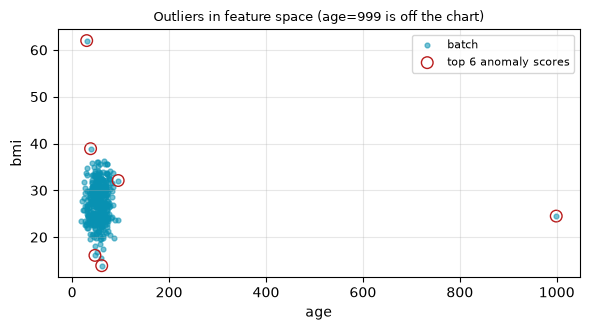

max age in batch: 999 - note the x axis is compressed by it


In [6]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.scatter(dirty.age, dirty.bmi, s=12, alpha=0.55, label="batch", color="#0891b2")
ax.scatter(flagged.age, flagged.bmi, s=70, facecolors="none", edgecolors="#b91c1c",
           label="top 6 anomaly scores")
ax.set_xlabel("age")
ax.set_ylabel("bmi")
ax.set_title("Outliers in feature space (age=999 is off the chart)", fontsize=9)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("max age in batch:", int(dirty.age.max()), "- note the x axis is compressed by it")

**Expected output** — a scatter plot where the legitimate rows form a cloud and the flagged rows sit at
the edges; the `age=999` point compresses the x axis, which is itself a useful visual warning that one
value can distort every summary statistic computed on the column.

### Step 5 — The gate: refuse, or accept with evidence

The ingestion job should return a decision plus the report. "Warn and continue" is how poisoned data
reaches a model.

In [7]:
def ingestion_gate(df: pd.DataFrame) -> dict:
    issues = validate(df)
    decision = "reject" if len(issues) else "accept"
    return {
        "decision": decision,
        "issues": len(issues),
        "rows": len(df),
        "report": issues,
    }


for name, batch in [("clean", clean), ("dirty", dirty)]:
    result = ingestion_gate(batch)
    print(f"{name:5} -> {result['decision']:6} with {result['issues']} issue(s)")

assert ingestion_gate(dirty)["decision"] == "reject"
print("\nDirty batch report:")
ingestion_gate(dirty)["report"]

clean -> accept with 0 issue(s)
dirty -> reject with 3 issue(s)

Dirty batch report:


,column,check,detail
0,record_id,unique,1 duplicated ids
1,age,max,1 above 105: [999]
2,site,allowed,unexpected values ['north ']


**Expected output** — `clean -> accept`, `dirty -> reject`, then the three-row report. In production the
report is written to the audit store (Module 18) so that a rejected batch is evidence of a control that
worked, not a support ticket.

## Exercises

1. **Add a cross-field rule.** Reject rows where `label == 1` but `age < 25`, and explain why such a rule
   belongs to the domain layer rather than the statistical one.
2. **Tune contamination.** Run the isolation forest with `contamination` at 0.005, 0.02 and 0.1. Plot the
   number of flagged rows against the number of true corruptions (5). What is the cost of each setting?
3. **Catch the trailing space.** Add a normalisation step for `site` and show that it converts an issue
   into a clean value. Should normalisation run before or after validation?
4. **Write the rejection policy.** Decide what happens on `reject`: fail the job, quarantine the batch, or
   accept with the bad rows dropped. Defend your choice with the poisoning material from Module 07.

## Reflection questions

1. Which of the four injected faults would a schema-only validator miss, and what does that say about
   "we validate our data"?
2. The anomaly score flagged a legal-but-odd row. Is that a success or a false positive? It depends on
   what, exactly?
3. Why must a rejected batch's report be retained rather than logged and discarded?

## References

1. Liu, F., Ting, K. and Zhou, Z., "Isolation Forest", ICDM 2008.
2. Schelter, S. et al., "Automating Large-Scale Data Quality Verification", VLDB 2018.
3. NIST, *AI RMF 1.0*, NIST AI 100-1, 2023 — Measure 2.2 (data quality).
4. OWASP, *Top 10 for LLM Applications*, 2025 — LLM04 (data and model poisoning).